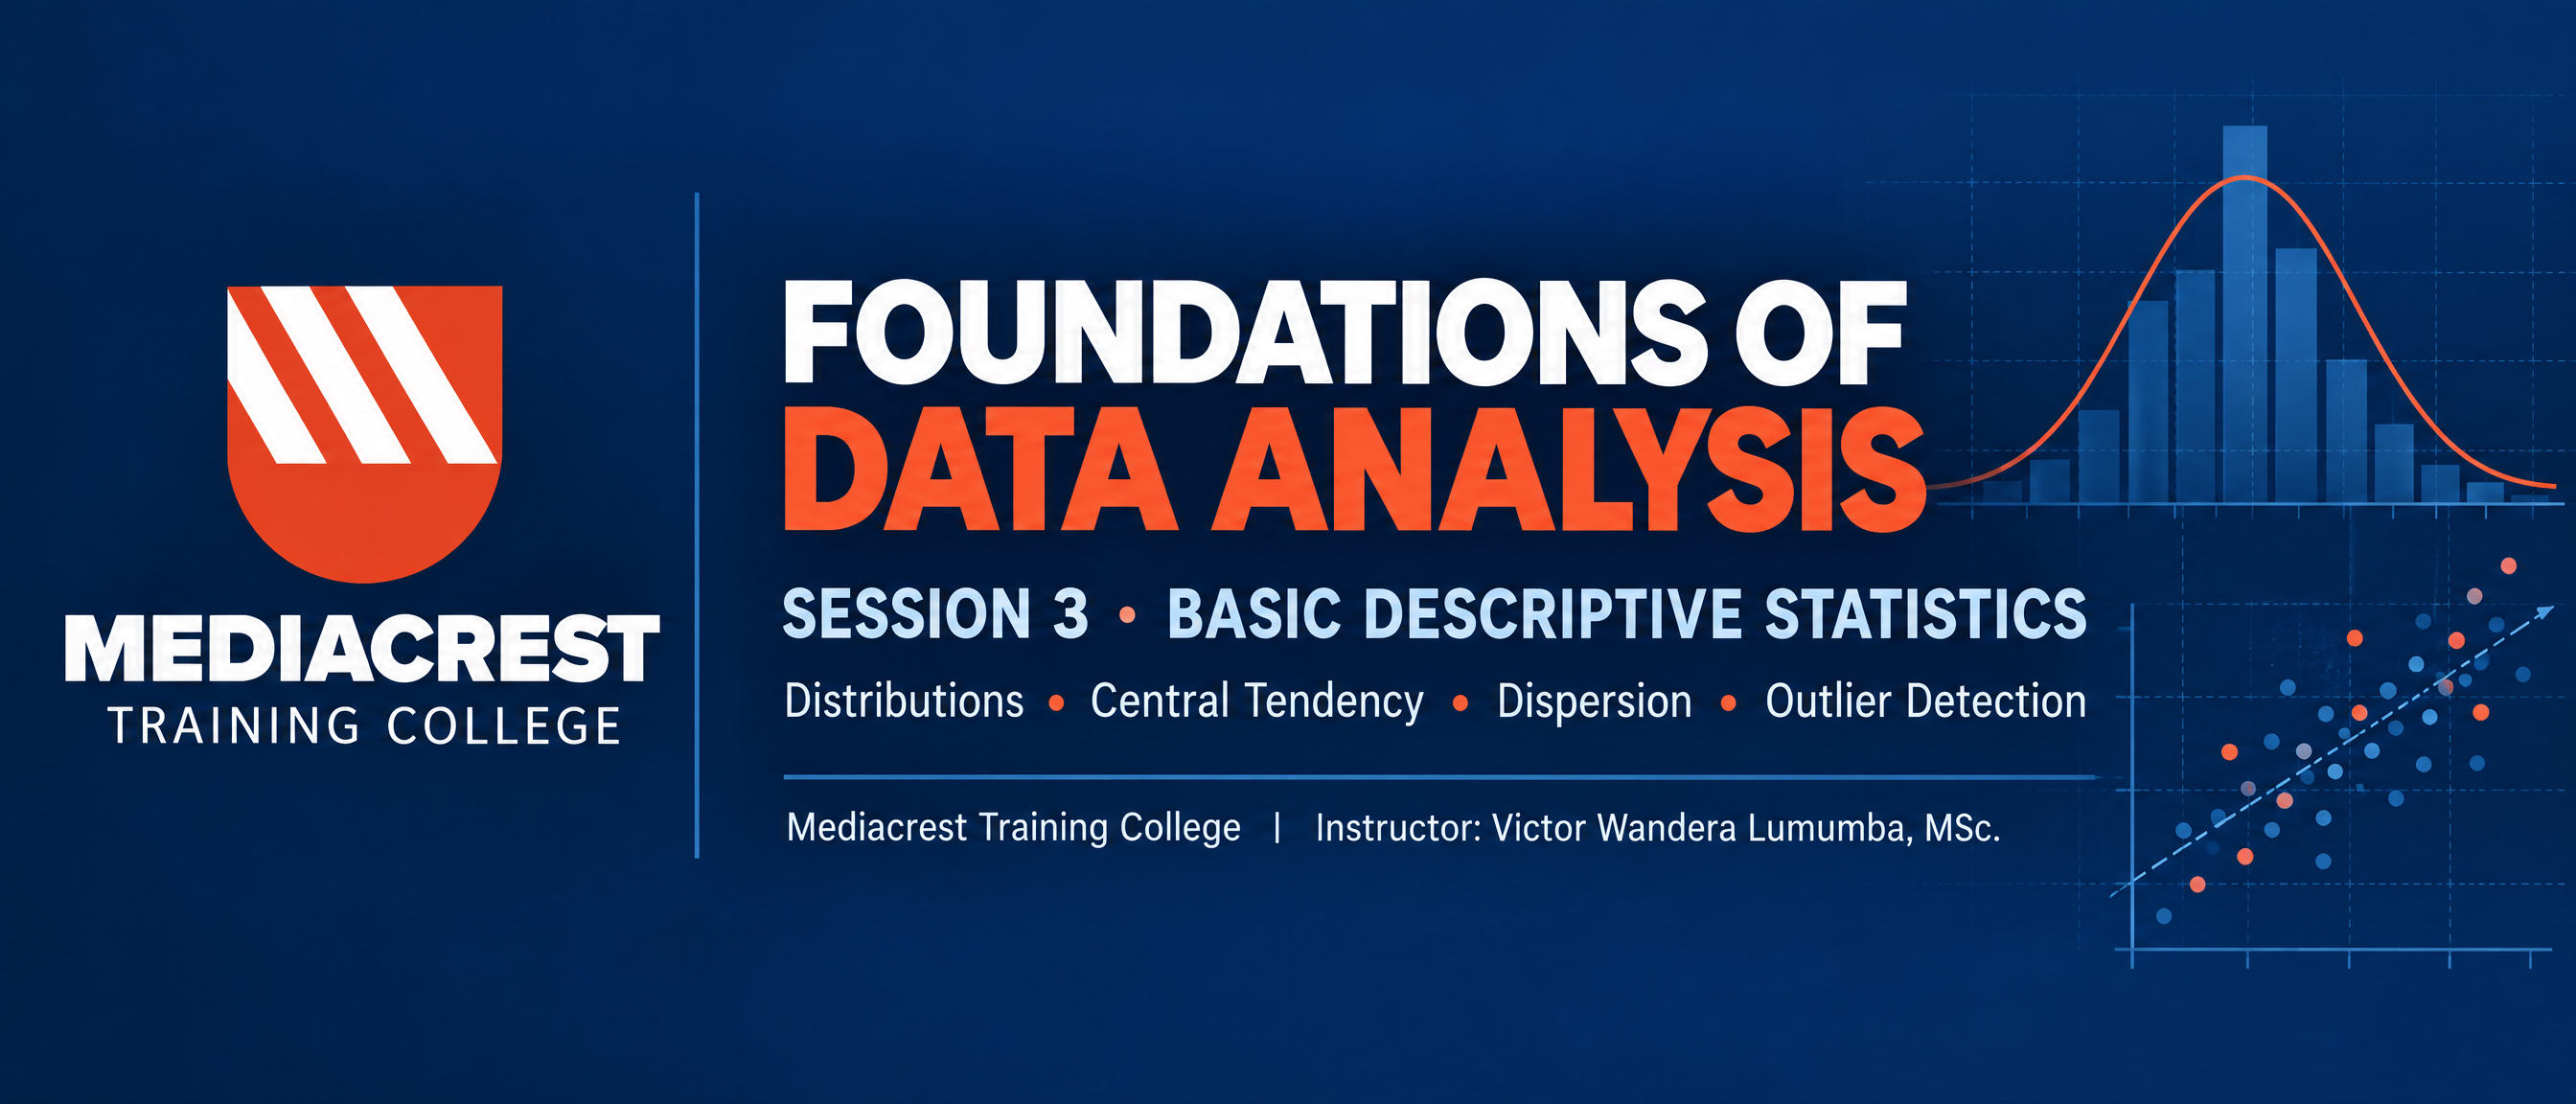

## **Foundations of Data Analysis: Session 3 - Basic Descriptive Statistics**
**College:** Mediacrest Training College

**Instructor:** Victor Wandera Lumumba, MSc.  

**Objective:** Transition from data collection to statistical thinking by mastering data distributions, central tendency, dispersion, and outlier detection.

### **Load the Required Libraries**

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### **Set visualization style**

In [18]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### **Load Datasets**
#### **1. Churn Detection Data (Assigning inferred column names based on data structure)**

In [19]:
churn_df = pd.read_csv('churn_detection_data.csv')
churn_df.head()

,Customer_ID,Age,Gender,Marital_Status,Education_Level,Employment_Status,Account_Tenure_Months,Account_Type,Number_of_Products,Average_Balance,Monthly_Transactions,Online_Banking_Usage,Mobile_Banking_Usage,Number_of_Complaints,Complaint_Resolution_Rate,Customer_Support_Calls,Email_Opt_In,Credit_Card_Holder,Loan_Account_Holder,Churn
0,CUST2463,32,Male,Divorced,Primary,Employed,13,Current,2,57001,19,6,10,0,0.97,0,1,0,0,1
1,CUST2511,45,Male,Single,University,Employed,88,Current,1,24533,14,5,9,0,0.89,2,1,0,0,0
2,CUST2227,29,Female,Single,Primary,Employed,151,Savings,3,212133,16,11,7,1,0.71,2,1,0,0,0
3,CUST0526,49,Female,Single,Secondary,Employed,118,Savings,2,94045,22,12,8,0,0.89,0,1,0,0,0
4,CUST0195,33,Female,Single,Primary,Employed,108,Savings,1,137693,15,7,8,0,0.64,1,0,0,0,0


In [28]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Customer_ID                10000 non-null  object 
 1   Age                        10000 non-null  int64  
 2   Gender                     10000 non-null  object 
 3   Marital_Status             10000 non-null  object 
 4   Education_Level            8974 non-null   object 
 5   Employment_Status          10000 non-null  object 
 6   Account_Tenure_Months      10000 non-null  int64  
 7   Account_Type               10000 non-null  object 
 8   Number_of_Products         10000 non-null  int64  
 9   Average_Balance            10000 non-null  int64  
 10  Monthly_Transactions       10000 non-null  int64  
 11  Online_Banking_Usage       10000 non-null  int64  
 12  Mobile_Banking_Usage       10000 non-null  int64  
 13  Number_of_Complaints       10000 non-null  int6

### **2. HTN Data (Medical dataset, assuming no headers)**

In [20]:
htn_df = pd.read_csv('htn_dat.csv')
print("Data loaded successfully!")
print(f"Churn Dataset Shape: {churn_df.shape}")
print(f"HTN Dataset Shape: {htn_df.shape}")

Data loaded successfully!
Churn Dataset Shape: (10000, 20)
HTN Dataset Shape: (4999, 16)


### **🧠 Part 1: Foundations (Population vs. Sample)**

#### **Part 1: Population vs. Sample**
**Population:** The entire group you want to draw conclusions about.  
**Sample:** A specific subset of the population that you actually analyze.  

### **Rule of Thumb: Greek letters (μ, σ) denote population parameters; Roman letters (x̄, s) denote sample statistics.**

> ## **`Demonstration: Sampling from the Churn Dataset`**

In [21]:
population_age = churn_df['Age'].dropna()
population_age

0       32
1       45
2       29
3       49
4       33
        ..
9995    32
9996    18
9997    47
9998    27
9999    27
Name: Age, Length: 10000, dtype: int64

In [22]:
population_age.info()

<class 'pandas.core.series.Series'>
RangeIndex: 10000 entries, 0 to 9999
Series name: Age
Non-Null Count  Dtype
--------------  -----
10000 non-null  int64
dtypes: int64(1)
memory usage: 78.3 KB


> ## **`Draw a random sample of 100 customers`**

In [23]:
sample_age = population_age.sample(n=100, random_state=42)
sample_age.info()

<class 'pandas.core.series.Series'>
Index: 100 entries, 6252 to 7231
Series name: Age
Non-Null Count  Dtype
--------------  -----
100 non-null    int64
dtypes: int64(1)
memory usage: 1.6 KB


In [24]:
print(f"Population Mean Age (μ): {population_age.mean():.2f}")
print(f"Sample Mean Age (x̄):   {sample_age.mean():.2f}")
print("\nNotice how the sample mean is a close estimate of the population mean.")

Population Mean Age (μ): 35.16
Sample Mean Age (x̄):   34.86

Notice how the sample mean is a close estimate of the population mean.


### **🧪 Lab Exercise 1: The Pitfall of the Mean**

### **Lab Exercise 1: Central Tendency & The Outlier Pitfall**

- Let's look at the "Daily Sales" dataset from the presentation to see how a single outlier skews the Mean.

> ## **`Dataset from Lab Exercise 1`**

In [25]:
mean_sales = np.mean(daily_sales)
median_sales = np.median(daily_sales)
mode_sales = pd.Series(daily_sales).mode()[0]

print(f"Mean:   {mean_sales}")
print(f"Median: {median_sales}")
print(f"Mode:   {mode_sales}")

Mean:   155.0
Median: 117.5
Mode:   110


## **Insight**
The '500' outlier drastically pulls the Mean (155.0) up, making it a poor representation of a 'typical' sales day. The Median (117.5) is much more robust.")

### **📊 Part 2 & 3: Dispersion & Real-World Application**
#### **Part 2 & 3: Dispersion (Spread)**

* The center doesn't tell the whole story. We must measure how spread out the data is using Range, Variance, Standard Deviation, and IQR.

> ## **`Analyze Customer 'Balance' from the Churn Dataset`**

In [29]:
balance = churn_df['Average_Balance'].dropna()

> ## **`Central Tendency`**

In [30]:
print("--- Central Tendency (Customer Balance) ---")
print(f"Mean:   {balance.mean():.2f}")
print(f"Median: {balance.median():.2f}")
print(f"Mode:   {balance.mode()[0]}")

--- Central Tendency (Customer Balance) ---
Mean:   150108.31
Median: 103650.50
Mode:   500


> ## **`Dispersion`**

In [31]:
print("\n--- Dispersion (Customer Balance) ---")
print(f"Range:    {balance.max() - balance.min():.2f}")
print(f"Variance: {balance.var():.2f}")
print(f"Std Dev:  {balance.std():.2f}")


--- Dispersion (Customer Balance) ---
Range:    1643580.00
Variance: 22898065692.34
Std Dev:  151321.07


In [32]:
q1 = balance.quantile(0.25)
q3 = balance.quantile(0.75)
iqr = q3 - q1
print(f"IQR:      {iqr:.2f} (The middle 50% of customers)")

IQR:      162339.00 (The middle 50% of customers)


### **📈 Part 4: Position, Shape & Histograms**
#### **Part 4: Reading a Distribution (Histograms & Skewness)**

* Histograms show the frequency of continuous data. We look for Center, Spread, Shape, and Outliers.


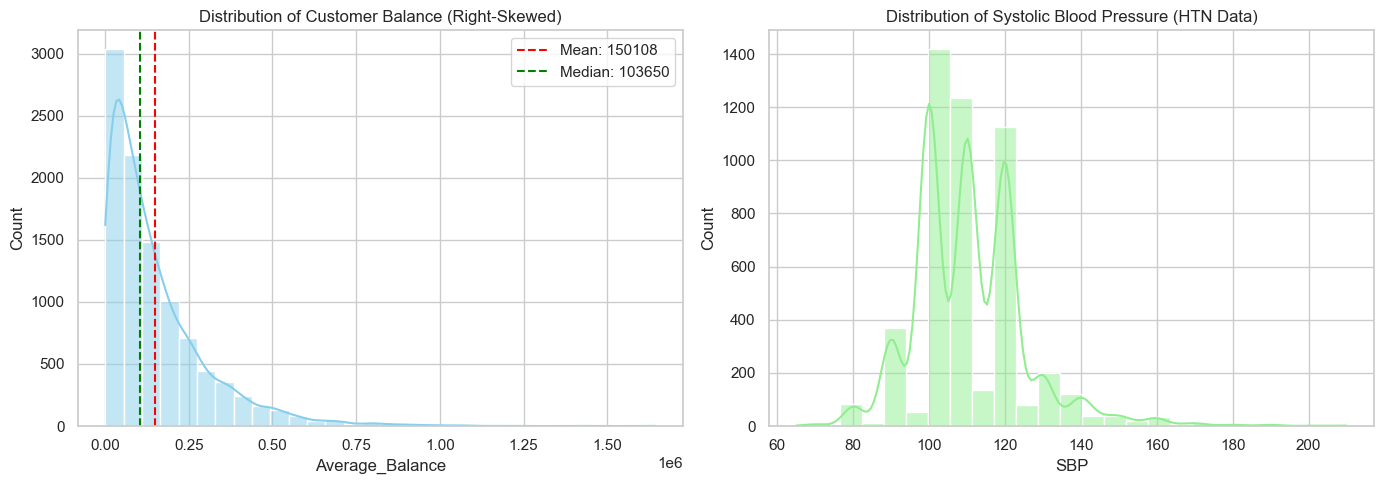

In [34]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Balance Distribution
sns.histplot(balance, 
             bins=30, 
             kde=True, 
             ax=axes[0], 
             color='skyblue')
axes[0].axvline(balance.mean(), 
                color='red', linestyle='--', 
                label=f'Mean: {balance.mean():.0f}')
axes[0].axvline(balance.median(), color='green', 
                linestyle='--', 
                label=f'Median: {balance.median():.0f}')
axes[0].set_title('Distribution of Customer Balance (Right-Skewed)')
axes[0].legend()

# 2. HTN Systolic Blood Pressure Distribution
sns.histplot(htn_df['SBP'].dropna(), bins=25, kde=True, ax=axes[1], color='lightgreen')
axes[1].set_title('Distribution of Systolic Blood Pressure (HTN Data)')

plt.tight_layout()
plt.show()

In [35]:
print(f"Skewness of Customer Balance: {balance.skew():.2f}")
print("💡 A positive skewness (>0) confirms the data is right-skewed (tail pulls to the right).")

Skewness of Customer Balance: 2.07
💡 A positive skewness (>0) confirms the data is right-skewed (tail pulls to the right).


### **🔍 Part 5: Outlier Detection (The IQR Rule)**

#### **Part 5: Outlier Detection (Tukey's IQR Rule)**

* A non-parametric, robust way to find outliers without assuming a normal distribution.
**Lower Bound:** Q1 - 1.5 × IQR  
**Upper Bound:** Q3 + 1.5 × IQR

Lower Bound: -199286.50
Upper Bound: 450069.50
Number of Outliers Detected: 503


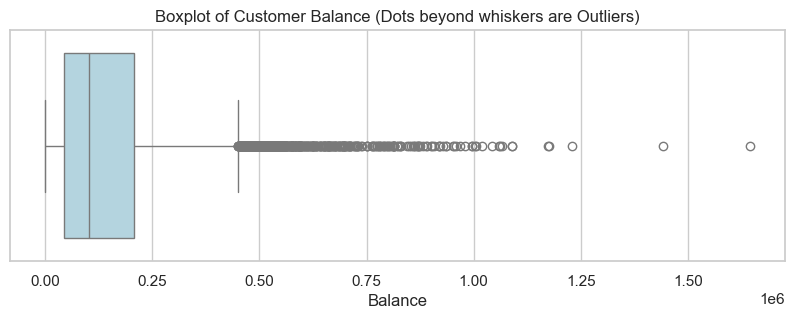

In [36]:
# Calculate Bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify Outliers
outliers = balance[(balance < lower_bound) | (balance > upper_bound)]

print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers Detected: {len(outliers)}")

# Visualize with a Boxplot
plt.figure(figsize=(10, 3))
sns.boxplot(x=balance, color='lightblue')
plt.title('Boxplot of Customer Balance (Dots beyond whiskers are Outliers)')
plt.xlabel('Balance')
plt.show()

### **🔗 Part 6: Correlation ≠ Causation**
#### **Part 6: Correlation ≠ Causation**

* Just because two variables move together does not mean one causes the other. Always question hidden confounding variables!

> ## **`Calculate Correlation Matrix for numeric features in Churn Data`**

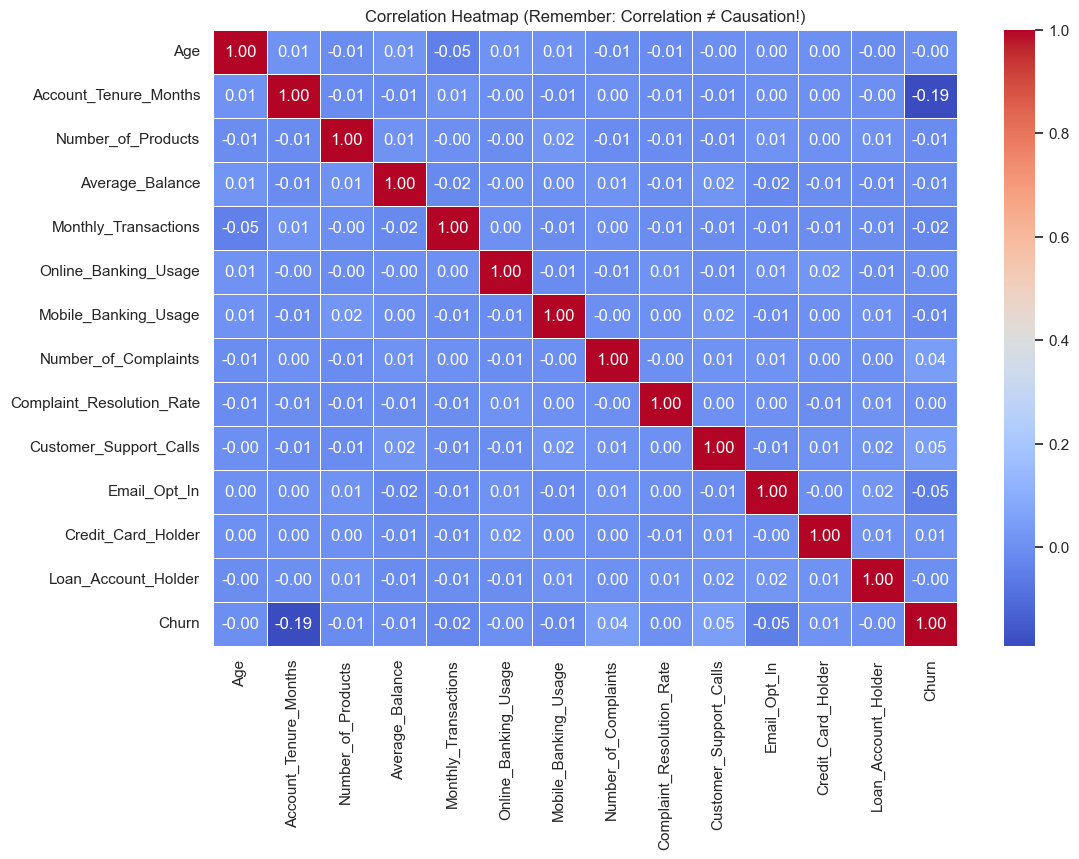

In [37]:
numeric_cols = churn_df.select_dtypes(include=[np.number]).columns
corr_matrix = churn_df[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap (Remember: Correlation ≠ Causation!)')
plt.show()

### **📑 Session Deliverable: Descriptive Statistics Summary Sheet**

#### **📌 Deliverable: Descriptive Statistics Summary Sheet**

**Context:** The business wants to understand the "typical" customer balance to inform marketing strategies.


> ## **`1. Generate the Summary Table`**

In [41]:
summary_data = {
    'Statistic': ['Mean', 'Median', 'Mode', 'Std Dev', 
                  'Min', 'Max', 'Q1 (25%)', 'Q3 (75%)', 
                  'IQR', 'Skewness', 'Outlier Count'],
    'Value': [
        f"{balance.mean():.2f}",
        f"{balance.median():.2f}",
        f"{balance.mode()[0]}",
        f"{balance.std():.2f}",
        f"{balance.min():.2f}",
        f"{balance.max():.2f}",
        f"{q1:.2f}",
        f"{q3:.2f}",
        f"{iqr:.2f}",
        f"{balance.skew():.2f}",
        len(outliers)
    ]
}
summary_df = pd.DataFrame(summary_data)

In [42]:
print("="*50)
print("DESCRIPTIVE STATISTICS SUMMARY SHEET")
print("Target Variable: Customer Balance")
print("="*50)
print(summary_df.to_string(index=False))

DESCRIPTIVE STATISTICS SUMMARY SHEET
Target Variable: Customer Balance
    Statistic      Value
         Mean  150108.31
       Median  103650.50
         Mode        500
      Std Dev  151321.07
          Min     500.00
          Max 1644080.00
     Q1 (25%)   44222.00
     Q3 (75%)  206561.00
          IQR  162339.00
     Skewness       2.07
Outlier Count        503


> ## **`2. Business Interpretation (5-Bullet Summary)`**

In [44]:
print("\n📊 BUSINESS INTERPRETATION & ACTIONABLE INSIGHTS:")
print("1. Skewness Alert: The data is heavily right-skewed. A few high-net-worth executives/founders are pulling the mean up.")
print("2. The 'Typical' Customer: The median balance is a much more accurate representation of the 'typical' customer than the mean.")
print("3. Ethical Marketing: Using the mean to advertise 'average customer balance' would be misleading and unethical.")
print("4. Outlier Investigation: The IQR rule flagged outliers. These should be kept but investigated (e.g., are they corporate accounts?).")
print("5. Spread Reliability: The large Standard Deviation and IQR indicate high variability; segmentation strategies are required rather than a one-size-fits-all approach.")


📊 BUSINESS INTERPRETATION & ACTIONABLE INSIGHTS:
1. Skewness Alert: The data is heavily right-skewed. A few high-net-worth executives/founders are pulling the mean up.
2. The 'Typical' Customer: The median balance is a much more accurate representation of the 'typical' customer than the mean.
3. Ethical Marketing: Using the mean to advertise 'average customer balance' would be misleading and unethical.
4. Outlier Investigation: The IQR rule flagged outliers. These should be kept but investigated (e.g., are they corporate accounts?).
5. Spread Reliability: The large Standard Deviation and IQR indicate high variability; segmentation strategies are required rather than a one-size-fits-all approach.
